In [1]:
# Step 1: Organize content by release year
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/netflix_cleaned.csv")
print("Release years:", df["release_year"].min(), "to", df["release_year"].max())
df = df.sort_values("release_year")
df[["title", "type", "release_year"]].head()

Release years: 1925 to 2021


,title,type,release_year
421,Pioneers: First Women Filmmakers*,TV Show,1925
6037,The Battle of Midway,Movie,1942
5698,Prelude to War,Movie,1942
6422,Undercover: How to Operate Behind Enemy Lines,Movie,1943
6510,WWII: Report from the Aleutians,Movie,1943


In [2]:
# Step 2: Calculate yearly content releases
yearly = df.groupby("release_year").size()
yearly_recent = yearly.loc[2000:]
print(yearly_recent)

release_year
2000      37
2001      45
2002      51
2003      59
2004      64
2005      80
2006      96
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
dtype: int64


In [3]:
# Step 3: Identify growth and decline trends
growth = (yearly_recent.pct_change() * 100).round(1)
trend = pd.DataFrame({"Titles": yearly_recent, "Growth %": growth})
print("Peak year:", yearly.idxmax(), "with", yearly.max(), "titles")
print("Biggest yearly increase:", growth.idxmax(), f"({growth.max()}%)")
print("Biggest yearly decrease:", growth.idxmin(), f"({growth.min()}%)")
trend.tail(12)

Peak year: 2018 with 1146 titles
Biggest yearly increase: 2016 (62.3%)
Biggest yearly decrease: 2021 (-37.9%)


,Titles,Growth %
release_year,,
2010,192,26.3
2011,185,-3.6
2012,236,27.6
2013,286,21.2
2014,352,23.1
2015,555,57.7
2016,901,62.3
2017,1030,14.3
2018,1146,11.3


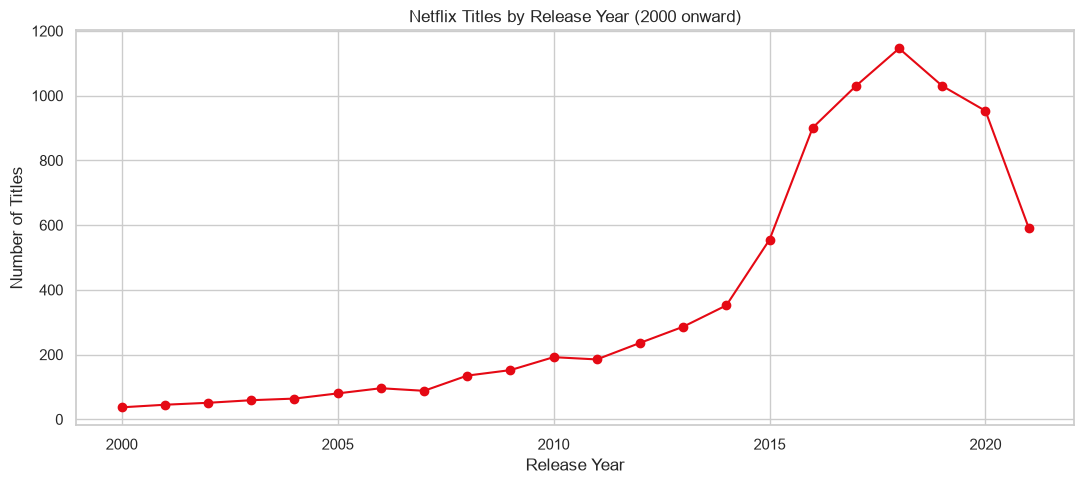

In [4]:
# Step 4a: Trend visualization - titles released per year
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 5))
plt.plot(yearly_recent.index, yearly_recent.values, marker="o", color="#E50914")
plt.title("Netflix Titles by Release Year (2000 onward)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("release_year_trend.png", dpi=150)
plt.show()

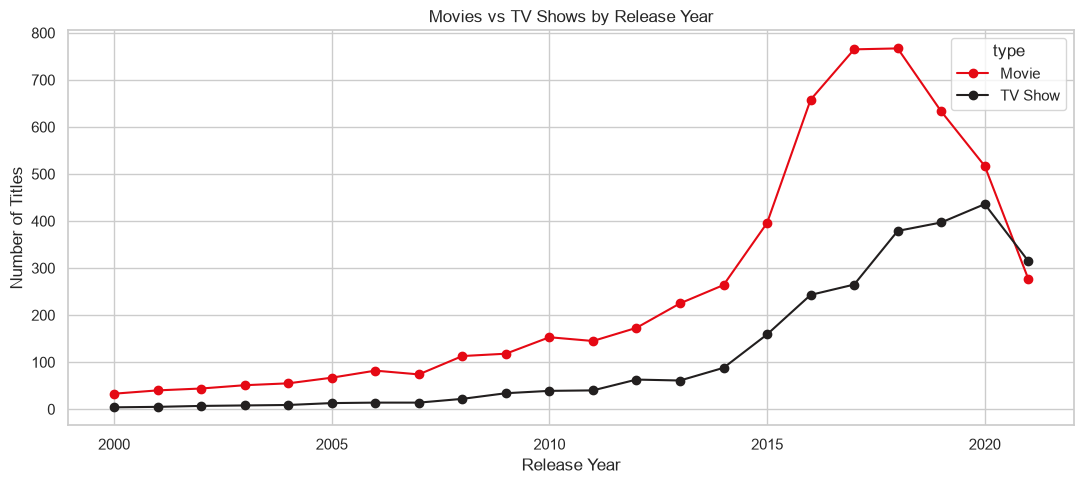

In [5]:
# Step 4b: Movies vs TV Shows by release year
by_type = df[df["release_year"] >= 2000].groupby(["release_year", "type"]).size().unstack(fill_value=0)
by_type.plot(figsize=(11, 5), marker="o", color=["#E50914", "#221F1F"])
plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("release_year_by_type.png", dpi=150)
plt.show()

In [6]:
# Step 5: Interpret business patterns
since_2015 = (df["release_year"] >= 2015).mean() * 100
print(f"{since_2015:.1f}% of all titles were released in 2015 or later.")
print("Peak year:", yearly.idxmax(), "with", yearly.max(), "titles")
print("Titles released in the last 3 years in the data:")
print(yearly.tail(3))

70.6% of all titles were released in 2015 or later.
Peak year: 2018 with 1146 titles
Titles released in the last 3 years in the data:
release_year
2019    1030
2020     953
2021     592
dtype: int64


## Key Findings

- Netflix titles by release year grew steadily from 192 titles in 2010 to a peak of 1,146 titles in 2018.
- The fastest growth came in 2015 and 2016, with increases of 57.7% and 62.3%. 2016 was the biggest yearly jump, and the library roughly tripled between 2014 and 2017.
- Growth slowed after 2016 (14.3% in 2017 and 11.3% in 2018), then titles declined in 2019 (-10.1%) and 2020 (-7.5%).
- The biggest decrease was 2021 (-37.9%, 592 titles). This is likely because the dataset covers only part of 2021, so it should not be read as a real collapse in production.
